In [79]:
%pip install numpy matplotlib nbconvert pandadoc scipy lalsuite gwpy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono

Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Linear Kalman Filter: Ballistic Projectile Model 1D

BallisticLinearModel(KalmanLinearModel) @ fs=256Hz

    Ballistic State Model (v1.3)
        Linear constant-acceleration toy model; position
        measured.

    Dimensions Summary:
        Observation.....................................: 1 dim
        State Vector....................................: 3 dims
        Control Input...................................: 0 dims

    Initial State:
        State Vector (x0)...............................: 3x1 dims
        State Covariance (P0)...........................: 3x3 dims

    Linear Model Structure (n=3, m=1, l=0):
        F (or A) (state transition      ) : 3x3 dims
        H (or C) (measurement map       ) : 1x3 dims
        B   (control map           ) : N/A
        L   (proc-noise influence  ) : N/A
        M   (meas-noise influence  ) : N/A

        Q (or W) (process covariance    ) : 3x3 dims
        R (or V) (measurement covariance) : 1x1 dims

Chrono summary:
 1. Model initialized: 0.000018s (ΔT=0.000018s)
 2. Sampling co

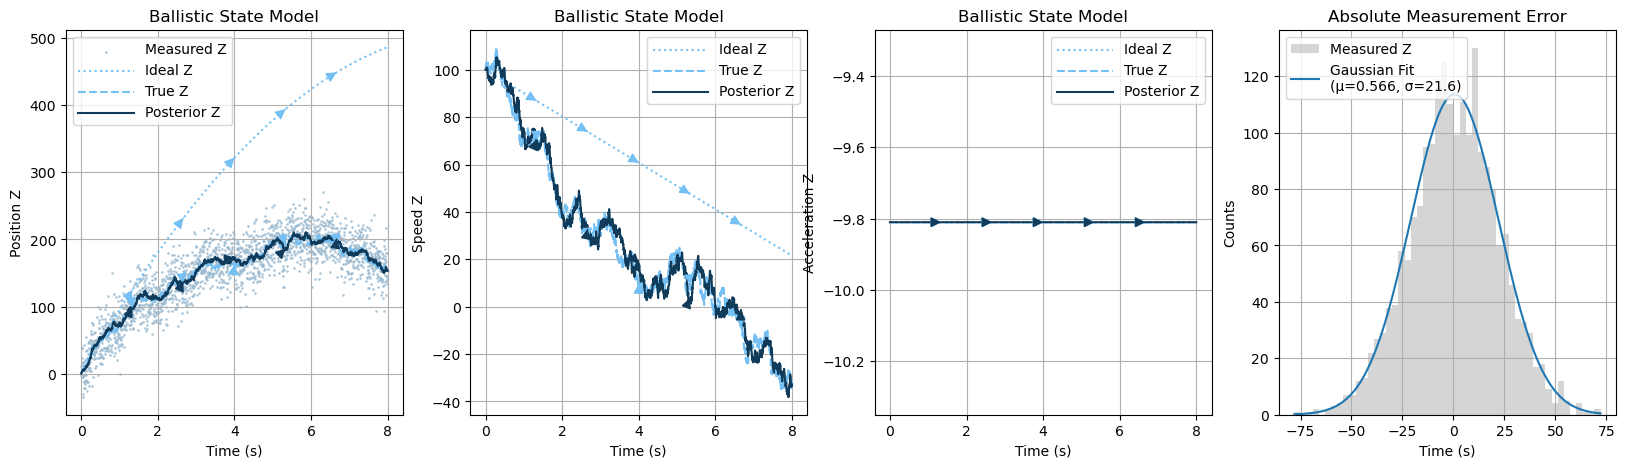

In [80]:
from kalman.apps.ballistics import BallisticLinearModel

# Initialize the model
bulletbill = BallisticLinearModel("Z", sample_rate=256, measurement_uncertainty=500, process_uncertainty=1, random_seed=42)
bulletbill.initial_state([0, 100, -9.81]) # Initial state: [z, vz, az]
bulletbill.print()

# Generate data and kalman-filter this data
chrono.restart()
chrono.lap("Model initialized")
sample = bulletbill.sample(8)
chrono.lap("Sampling completed")
record = bulletbill.filter(sample, smooth=True, reset=True)
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
canvas = get_canvas(4, 1)

# Plotting
record.plot(sample=sample, fig=canvas[0], component="position")
chrono.lap("Position plot completed")
record.plot(sample=sample, fig=canvas[1], component="speed")
chrono.lap("Speed plot completed")
record.plot(sample=sample, fig=canvas[2], component="acceleration")
chrono.lap("Acceleration plot completed")

record.plot_error(sample=sample, fig=canvas[3])
chrono.summary()

> ['Z']
> ['Z']
Sampling & filtering completed for #2/2: 0.197618s
KalmanStateCollection with 2 records: 
  0: KalmanStateRecord(N=2048, n=3, m=1, flavor=Posterior, model=Ballistic State Model)
  1: KalmanStateRecord(N=2048, n=3, m=1, flavor=Posterior, model=Ballistic State Model)


(<Axes: title={'center': 'Ballistic State Model'}, xlabel='Time (s)', ylabel='Position Z'>,
 <Axes: title={'center': 'Ballistic State Model'}, xlabel='Time (s)', ylabel='Position Z'>)

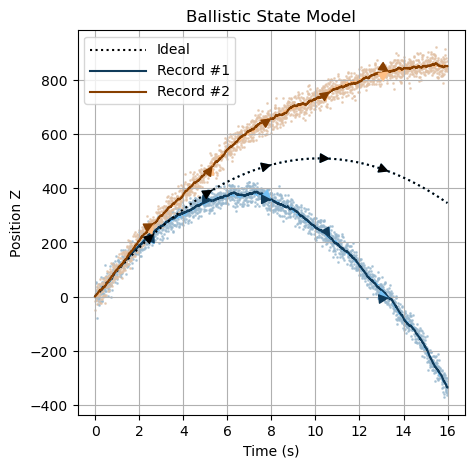

In [81]:
from kalman.apps.ballistics import BallisticLinearModel
from kalman.framework.io.collection import KalmanStateCollection

bulletbill = BallisticLinearModel("Z", sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5)
print(">", bulletbill.axis)
bulletbill.initial_state([0, 100, -9.81]) # Initial state: [z, vz, az]
print(">", bulletbill.axis)

chrono.restart()
chrono.lap("Model initialized")

N = 2
samples = []
collection = []
for i in range(N):

    samples.append(bulletbill.sample(16))
    collection.append(bulletbill.filter(samples[-1], smooth=True, reset=True))
    if i % 4 == 0 or i == N-1:
        print(chrono.lap(f"Sampling & filtering completed for #{i+1}/{N}"), end="\r" if i < N-1 else "\n")

collection = KalmanStateCollection(collection)
collection.print()

collection.plot(samples=samples, component="position")

## Linear Kalman Filter: Ballistic Projectile Model 3D

/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/framework/abstract/mixins.py:308: UserWarning: Initial state vector dimension expected 9x1, got 3x3. Resizing.
  warnings.warn(


KalmanStateRecord:

    Composite Kalman Model (v.1.0)
        Composite Kalman model combining multiple submodels.

    Summary:
        Samples...........................................: 2048 data points
        State Dimension (n)...............................: 9D
        Observation Dimension (m).........................: 3D
        Flavor............................................: Sampled
        Start Time........................................: 0s
        Duration..........................................: 16s

    Dimensions & Data Quality:
        Time (s) .........................................: [0s .. 16s[ (dtype=float64)
        Measurements (zk) ................................: 2048x(3x1) (dtype=float64)
        State Vector (xk) ................................: 2048x(9x1) (dtype=float64)
        State Covariance (Pk) ............................: 2048x(9x9) (dtype=float64)

KalmanStateRecord:

    Composite Kalman Model (v.1.0)
        Composite Kalman model comb

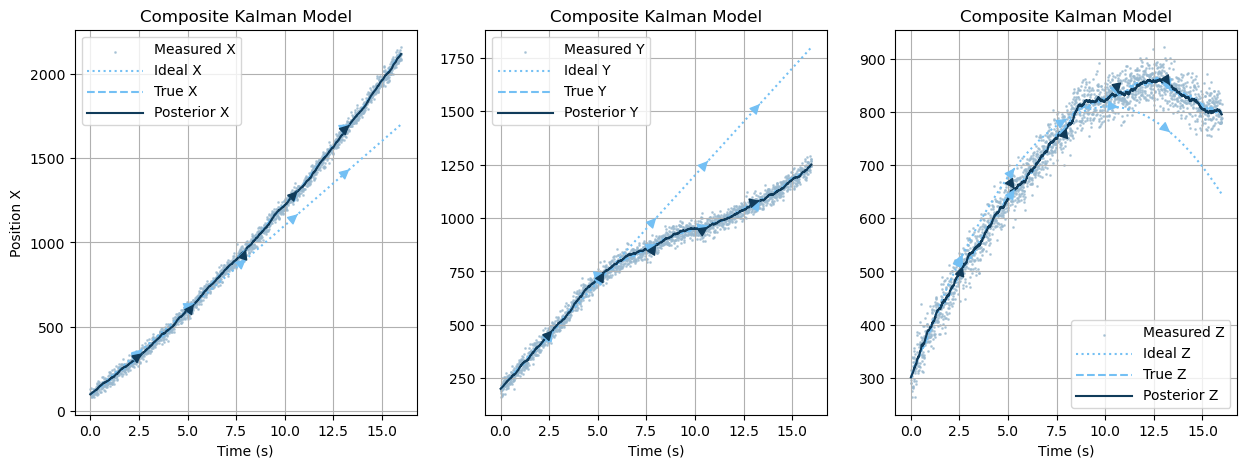

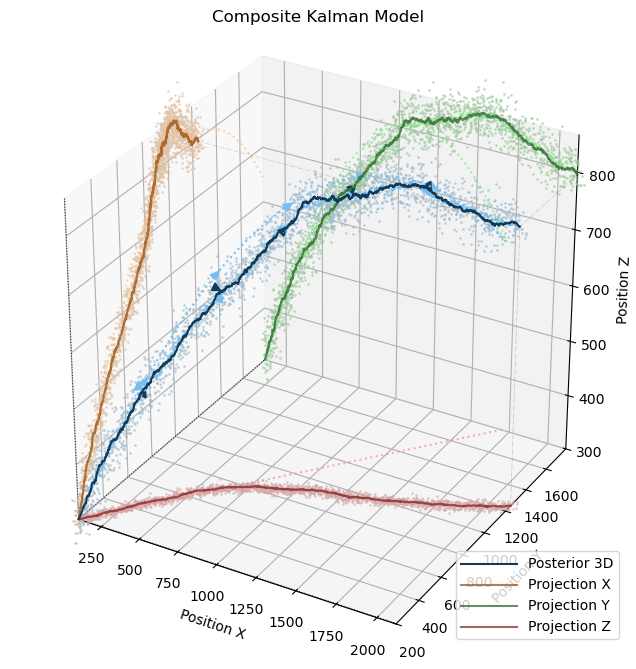

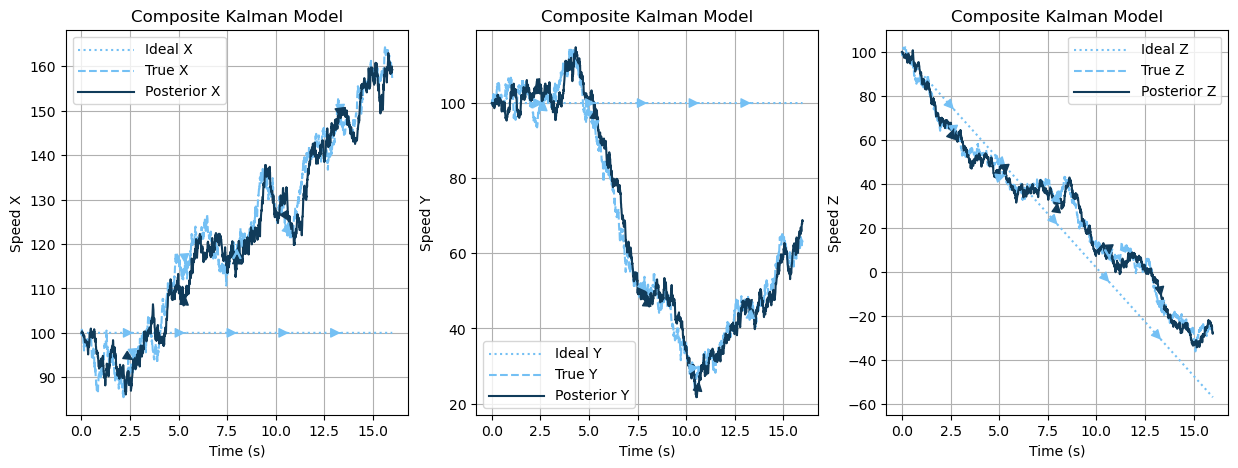

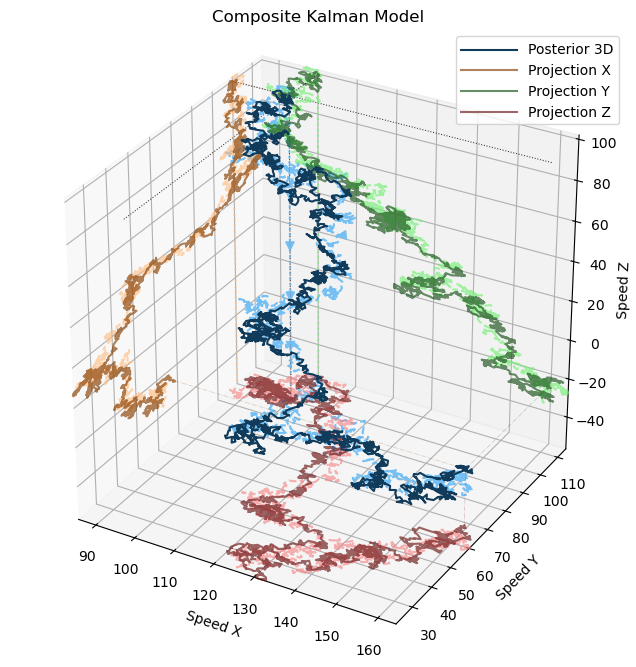

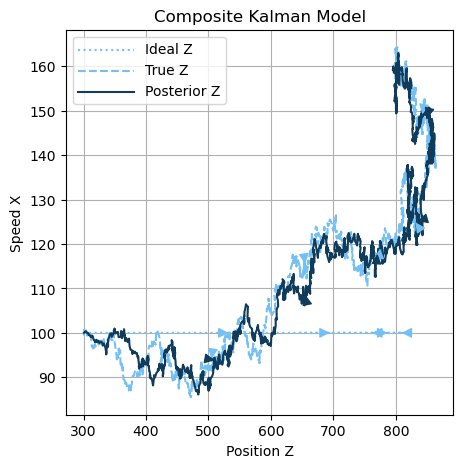

In [82]:
chrono.restart()

from kalman.apps.ballistics import BallisticLinearModel
from kalman.models.composite import KalmanCompositeModel
bulletbill = KalmanCompositeModel(
    BallisticLinearModel("X", sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42),
    BallisticLinearModel("Y", sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42),
    BallisticLinearModel("Z", sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42)
)

bulletbill.initial_state([
    [100, 100, 0],    # Initial state: [x, vx, ax] 
    [200, 100, 0],    # Initial state: [y, vy, ay]
    [300, 100, -9.81] # Initial state: [z, vz, az]
])
# bulletbill.print()
chrono.lap("Model initialized")

sample = bulletbill.sample(16)
chrono.lap("Sampling completed")

print(sample)
record = bulletbill.filter(sample.zk, smooth=True, reset=True)
record.print()
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
canvas = get_canvas(3, 1)
record.plot(sample=sample, component="position", dim=0, fig=canvas[0])
record.plot(sample=sample, component="position", dim=1, fig=canvas[1], sharey = True)
record.plot(sample=sample, component="position", dim=2, fig=canvas[2], sharey = True)
record.plot(sample=sample, component="position")
chrono.lap("Position plot completed")

canvas = get_canvas(3, 1)
record.plot(sample=sample, component="speed", dim=0, fig=canvas[0])
record.plot(sample=sample, component="speed", dim=1, fig=canvas[1])
record.plot(sample=sample, component="speed", dim=2, fig=canvas[2])
record.plot(sample=sample, component=["speed", "speed", "speed"])
chrono.lap("Speed plot completed")

record.plot(sample=sample, component=["position", "speed"], dim=[2,0])
chrono.lap("Correlation plot completed")

chrono.summary()

BallisticModel(KalmanExtendedModel) @ fs=128Hz

    Ballistic Extended Model (v1.0)
        Nonlinear 3D ballistic model with gravity, drag,
        and thrust.

    Dimensions Summary:
        Observation.....................................: 3 dims
        State Vector....................................: 9 dims
        Control Input...................................: 0 dims

    Initial State:
        State Vector (x0)...............................: 9x1 dims
        State Covariance (P0)...........................: 9x9 dims

    Metadata Entries:
        G      = 6.674e-11 (float)
        M      = 5.972e+24 (float)
        c_drag = 0 (int)
        m      = 1.0 (float)



IndexError: list index out of range

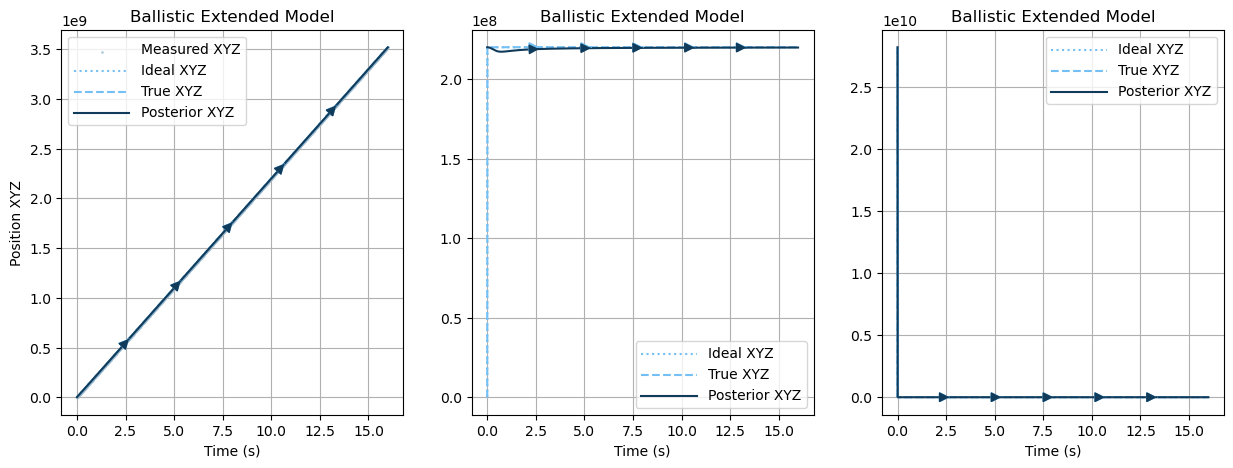

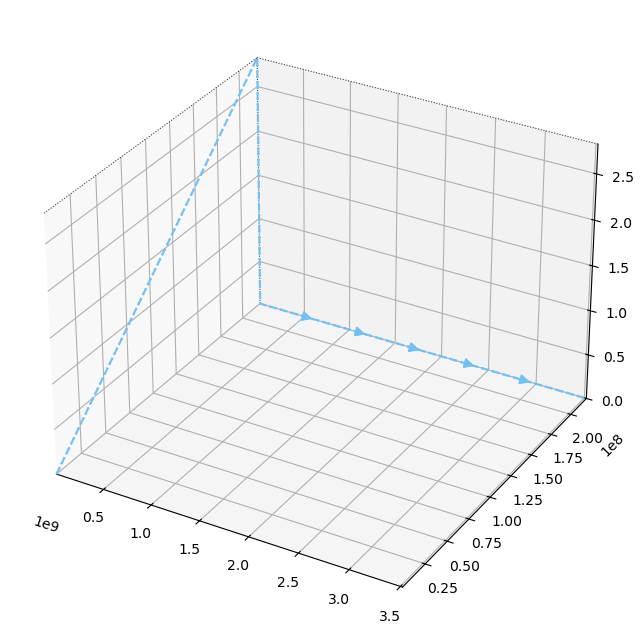

In [84]:
chrono.restart()

from kalman.apps.ballistics import BallisticModel
bulletbill = BallisticModel("XYZ", fs=128, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42)
bulletbill.initial_state([
    [100, 100, 0],    # Initial state: [x, vx, ax] 
    [200, 100, 0],    # Initial state: [y, vy, ay]
    [300, 100, -9.81] # Initial state: [z, vz, az]
])
bulletbill.print()
chrono.lap("Model initialized")

sample = bulletbill.sample(16)
chrono.lap("Sampling completed")

record = bulletbill.filter(sample.zk, smooth=False, reset=True)
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
canvas = get_canvas(3, 1)
record.plot(sample=sample, component="position", dim=0, fig=canvas[0])
record.plot(sample=sample, component="position", dim=1, fig=canvas[1], sharey = True)
record.plot(sample=sample, component="position", dim=2, fig=canvas[2], sharey = True)
record.plot(sample=sample, component="position")
chrono.lap("Position plot completed")

canvas = get_canvas(3, 1)
record.plot(sample=sample, component="speed", dim=0, fig=canvas[0])
record.plot(sample=sample, component="speed", dim=1, fig=canvas[1])
record.plot(sample=sample, component="speed", dim=2, fig=canvas[2])
record.plot(sample=sample, component=["speed", "speed", "speed"])
chrono.lap("Speed plot completed")

chrono.summary()

# Damped Harmonic Oscillator

Chrono summary:
 1. Model initialized: 0.000012s (ΔT=0.000012s)
 2. Sampling completed: 0.020594s (ΔT=0.020582s)
 3. Filtering completed: 0.217637s (ΔT=0.197043s)
 4. Position plot completed: 0.241923s (ΔT=0.024286s)
 5. Speed plot completed: 0.258441s (ΔT=0.016518s)

==> Total elapsed: 0.282969s



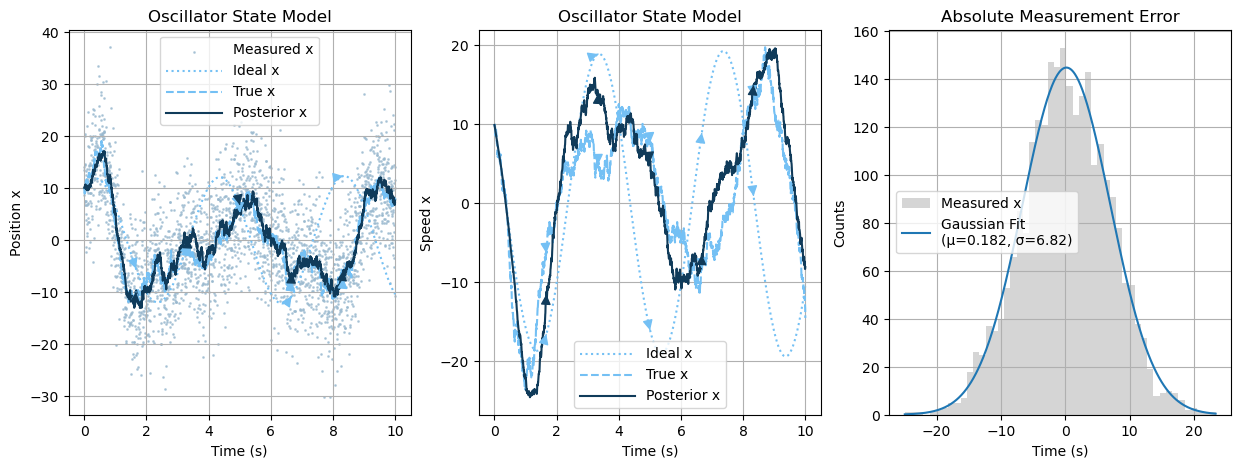

In [85]:
from kalman.apps.oscillators import OscillatorModel
import numpy as np

# Initialize the model
oscillator = OscillatorModel("x", sample_rate=256,
                                  w0=np.pi/2, Q=10000,
                                  measurement_uncertainty=50, process_uncertainty=0.1, random_seed=42)
oscillator.initial_state([10, 10]) # Initial state: [z, vz]
# oscillator.print()

# Generate data and kalman-filter this data
chrono.restart()
chrono.lap("Model initialized")
sample = oscillator.sample(10)
chrono.lap("Sampling completed")
record = oscillator.filter(sample, smooth=True, reset=True)
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
canvas = get_canvas(3, 1)

# Plotting
record.plot(sample=sample, fig=canvas[0], component=["position"], ideal=False)
chrono.lap("Position plot completed")
record.plot(sample=sample, fig=canvas[1], component=["speed"], ideal=False)
chrono.lap("Speed plot completed")

record.plot_error(sample=sample, fig=canvas[2])
chrono.summary()

/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/framework/abstract/mixins.py:308: UserWarning: Initial state vector dimension expected 2x1, got 1x1. Resizing.
  warnings.warn(


AnalyticOscillatorModel(KalmanLinearModel) @ fs=256Hz

    Analytic Oscillator State Model (x + iy representation) (v1.0)
        State model for oscillatory motion, simulating the
        behavior of a simple harmonic oscillator.

    Dimensions Summary:
        Observation.....................................: 2 dims
        State Vector....................................: 2 dims
        Control Input...................................: 0 dims

    Initial State:
        State Vector (x0)...............................: 2x1 dims
        State Covariance (P0)...........................: 2x2 dims

    Linear Model Structure (n=2, m=2, l=0):
        F (or A) (state transition      ) : 2x2 dims
        H (or C) (measurement map       ) : 2x2 dims
        B   (control map           ) : N/A
        L   (proc-noise influence  ) : N/A
        M   (meas-noise influence  ) : N/A

        Q (or W) (process covariance    ) : 2x2 dims
        R (or V) (measurement covariance) : 2x2 dims



AssertionError: 

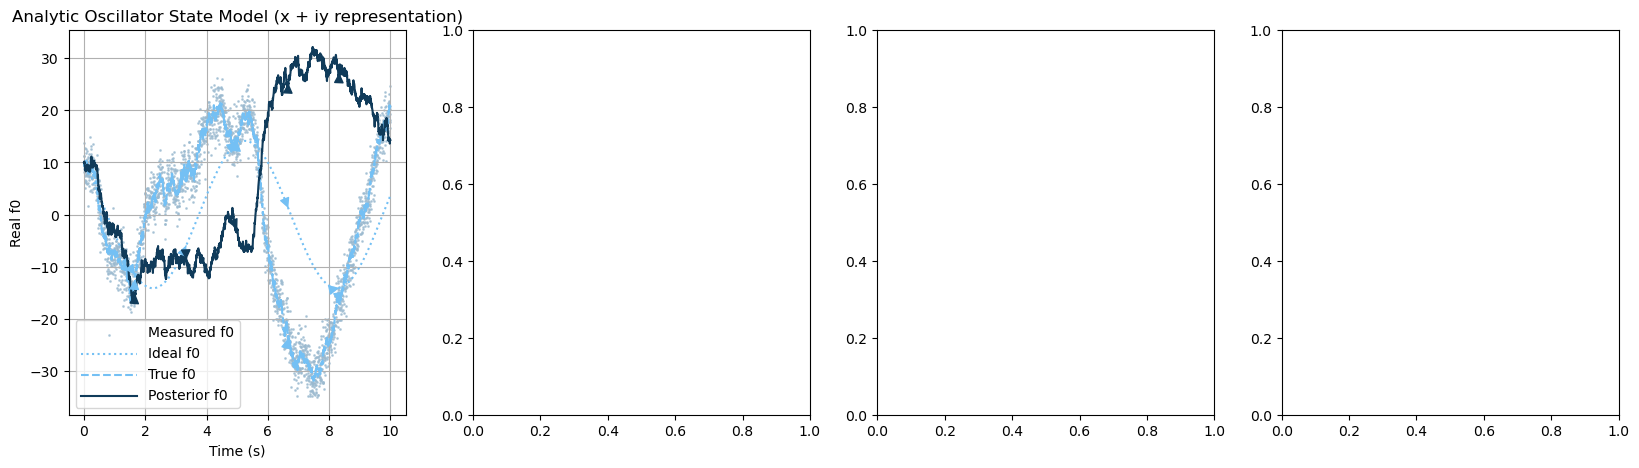

In [86]:
from kalman.apps.oscillators import AnalyticOscillatorModel
import numpy as np

# Initialize the model
analytic_oscillator = AnalyticOscillatorModel("f0", sample_rate=256,
                                  w0=np.pi/3, Q=10000, wc=np.pi/7,
                                  measurement_uncertainty=5, process_uncertainty=0.1, random_seed=42)
analytic_oscillator.initial_state([10]) # Initial state: [z]
analytic_oscillator.print()

# Generate data and kalman-filter this data
chrono.restart()
chrono.lap("Model initialized")
sample = analytic_oscillator.sample(10)

chrono.lap("Sampling completed")
record = analytic_oscillator.filter(sample, smooth=True, reset=True, preprocess=True)
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
canvas = get_canvas(4, 1)

# Plotting
record.plot(sample=sample, fig=canvas[0], component=["real"], view="1d")
chrono.lap("Real part plot completed")
record.plot(sample=sample, fig=canvas[1], component=["imag"], view="1d", dim=1)
chrono.lap("Imaginary part plot completed")
record.plot(sample=sample, fig=canvas[2], component=["real", "imag"])

record.plot_error(sample=sample, fig=canvas[3])
chrono.summary()

## Power Grid 50/60Hz Model

## Violin Suspension Model